![Banner](../images/09_03_banner_rs_rader.png)


# Sentinel-1 GRD Processing

*Dr.


## Overview

Zia U. Ahmed · Upatta Analytics LLC · uses GeoLattice's `geolattice.rsense` remote sensing subpackage*

A Sentinel-1 Ground Range Detected (GRD) product stores raw digital numbers in radar geometry. Turning it into comparable, map-ready backscatter takes several steps: thermal-noise removal, radiometric calibration, multilooking, speckle filtering, radiometric terrain flattening and terrain correction (geocoding), then a decibel conversion and a quality-control pass. This notebook runs every one of those steps on a **real** Sentinel-1A GRD scene over the Cox's Bazar -- Teknaf coast of Bangladesh (13 January 2024), using a real Copernicus DEM for the terrain steps, and reports the real numbers that come out: a measured noise floor, a measured speckle-filter ENL, and a terrain-flattening correction that traces the real hill ridges on the ground, not a synthetic stand-in for them.

Cox's Bazar is a deliberate choice of AOI: the Bay of Bengal gives a large, genuinely flat,
genuinely calm-water target for the noise-floor and speckle sections; the town, beach and
river mouth give mixed land cover; and the Teknaf peninsula's hills (up to about 400 m, real
relief inside an otherwise near-sea-level delta) give terrain flattening something real to
correct, directly testing the Rmd workflow's own claim that flattening "changes little" on a
flat plain but is "essential" where there is real topography.


## Core concepts

### Learning objectives

1. Run thermal-noise removal, radiometric calibration, multilooking, speckle filtering, terrain flattening and geocoding on the Sentinel-1A IW GRDH scene of 13 January 2024 over Cox's Bazar and Teknaf.
2. Calibrate digital numbers to sigma0, beta0 and gamma0 with the scene's calibration and noise look-up tables, passing the crop offset to `interpolate_lut`.
3. Measure the noise floor over the Bay of Bengal and the equivalent number of looks after a 3x3 multilook.
4. Compare boxcar, Lee, Refined Lee and Gamma-MAP filters on the multilooked VV image, using ENL on open water.
5. Flatten beta0 to gamma0 with `terrain_flatten` and the Copernicus DEM GLO-30, and read the correction on the coastal plain and on the Teknaf hills.
6. Geocode with `process_grd(backend="native")` from the product ground control points, and state which full-product annotation `process_grd(backend="sarsen")` needs for range-Doppler terrain correction.
7. Convert linear backscatter to decibels with `to_db` for display, and mask layover, shadow, the measured noise floor and image edges.

### Contents

1. Setup
2. Study area and real data
3. The GRD processing chain
4. Calibration and noise look-up tables
5. Geolocation, incidence angle and platform heading
6. Thermal-noise removal and radiometric calibration
7. Multilooking
8. Speckle filtering
9. Radiometric terrain flattening
10. Terrain correction (geocoding)
11. Convert to dB
12. Quality control
13. Processing back-ends
14. Bonus: analysis-ready alternatives, same AOI
15. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
import warnings  # control warning messages
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import rasterio  # raster reading and writing
import rasterio.warp as warp  # reprojection
from rasterio.windows import Window  # read a pixel window of a large file
# affine transform from ground control points; map coordinate -> (row, col)
from rasterio.transform import from_gcps, rowcol
import matplotlib.pyplot as plt  # figures
from scipy.ndimage import zoom  # resample arrays by interpolation

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.sar import sentinel1 as s1  # Sentinel-1 calibration, noise, multilook and geometry tools
from geolattice.rsense.sar import speckle  # speckle filters and ENL estimation

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
RUN_ONLINE = False  # set to True to run the online download example at the end
print("geolattice.rsense", rs.__version__)  # GeoLattice version

geolattice.rsense 0.3.49


## Study area and real data

**Scene:** `S1A_IW_GRDH_1SDV_20240113T115602_20240113T115627_052088_064BA4` -- Sentinel-1A,
IW mode, GRDH, VV+VH, ascending, 13 January 2024, 11:56 UTC (dry season). Downloaded from
Microsoft Planetary Computer's `sentinel-1-grd` collection, which republishes the real ESA
measurement GeoTIFFs plus real per-swath calibration and noise look-up tables as a STAC item
-- the same files a direct ESA/Copernicus download would give for those three pieces. Each
polarization's measurement file is close to 600 MB, so this cell downloads once and caches the
result under `data/`.

**AOI:** Cox's Bazar -- Teknaf, Bangladesh, `(91.85, 21.30, 92.15, 21.55)`. The Bay of Bengal
(open water), the Cox's Bazar peninsula and Bakkhali river mouth (urban, agriculture, tidal
flats) and the Teknaf peninsula's hills (real relief up to about 400 m) all fall inside one
small crop of the scene, read directly from the downloaded GeoTIFF with a `rasterio` windowed
read rather than loading the full roughly 26,000 x 16,700 pixel swath.

**DEM:** Copernicus DEM GLO-30 (30 m), mosaicked from the three tiles covering the AOI and
clipped with a small margin, from Planetary Computer's `cop-dem-glo-30` collection.


In [2]:
DATA = Path("../../../../Data/08_remote_sensing/08_03_radar")  # data folder
# the unzipped Sentinel-1A GRD product (SAFE folder)
SAFE_DIR = DATA / "S1A_IW_GRDH_1SDV_20240113T115602_20240113T115627_052088_064BA4.SAFE"
# common part of the file names inside the SAFE folder
STEM = "20240113t115602-20240113t115627-052088-064ba4-001"
# VV measurement GeoTIFF (raw digital numbers)
VV_PATH = SAFE_DIR / "measurement" / f"s1a-iw-grd-vv-{STEM}.tiff"
VH_PATH = SAFE_DIR / "measurement" / f"s1a-iw-grd-vh-{STEM}.tiff"  # VH measurement GeoTIFF
# VV calibration look-up table (XML)
CAL_VV = SAFE_DIR / "annotation" / "calibration" / f"calibration-s1a-iw-grd-vv-{STEM}.xml"
# VH calibration look-up table
CAL_VH = SAFE_DIR / "annotation" / "calibration" / f"calibration-s1a-iw-grd-vh-{STEM}.xml"
# VV thermal-noise look-up table (XML)
NOISE_VV = SAFE_DIR / "annotation" / "calibration" / f"noise-s1a-iw-grd-vv-{STEM}.xml"
# VH thermal-noise look-up table
NOISE_VH = SAFE_DIR / "annotation" / "calibration" / f"noise-s1a-iw-grd-vh-{STEM}.xml"
DEM_PATH = DATA / "cop_dem_glo30" / "coxsbazar_dem.tif"  # Copernicus 30 m DEM clipped to the AOI

AOI = (91.85, 21.30, 92.15, 21.55)   # Cox's Bazar -- Teknaf, Bangladesh

if not VV_PATH.exists():  # download only if the scene is not on disk yet
    # Real Sentinel-1A GRD scene and real Copernicus DEM tiles from Planetary Computer.
    # ~600 MB per polarization -- only runs once, cached under ../../../../Data/08_remote_sensing/08_03_radar/ after that.
    import pystac_client  # STAC search client
    import planetary_computer as pc  # signs Planetary Computer URLs so they can be downloaded
    import requests  # HTTP downloads

    # open the Planetary Computer STAC catalogue
    catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                        modifier=pc.sign_inplace)
    item = catalog.get_collection("sentinel-1-grd").get_item(  # the GRD item of 13 January 2024
        "S1A_IW_GRDH_1SDV_20240113T115602_20240113T115627_052088_064BA4")

    def fetch(href, dest):  # stream a file to disk in 1 MB chunks
        dest.parent.mkdir(parents=True, exist_ok=True)  # create the folder
        with requests.get(href, timeout=600, stream=True) as r:  # open the URL as a stream
            r.raise_for_status()  # stop on an HTTP error
            with open(dest, "wb") as f:  # write the file chunk by chunk
                for chunk in r.iter_content(chunk_size=1 << 20):  # 1 MB chunks
                    f.write(chunk)  # append the chunk

    # asset name in the STAC item -> local destination
    ASSETS = {"vv": VV_PATH, "vh": VH_PATH, "schema-calibration-vv": CAL_VV,
             "schema-calibration-vh": CAL_VH, "schema-noise-vv": NOISE_VV,
             "schema-noise-vh": NOISE_VH}
    for key, dest in ASSETS.items():  # download every asset
        print("downloading", key, "->", dest.name)  # progress message
        fetch(item.assets[key].href, dest)  # download the asset

    # Copernicus DEM tiles that touch the AOI
    dem_search = catalog.search(collections=["cop-dem-glo-30"], bbox=AOI)
    DEM_PATH.parent.mkdir(parents=True, exist_ok=True)  # DEM folder
    from rasterio.merge import merge  # mosaic several rasters into one

    tiles = []  # the opened DEM tiles
    for dem_item in dem_search.items():  # download each tile and open it
        tmp = DEM_PATH.parent / f"{dem_item.id}.tif"  # temporary file for this tile
        fetch(dem_item.assets["data"].href, tmp)  # download the tile
        tiles.append(rasterio.open(tmp))  # open it
    mosaic, mtransform = merge(tiles)  # merge the tiles into one array and its transform
    # pixel window of the AOI inside the mosaic
    win = rasterio.windows.from_bounds(*AOI, transform=mtransform).round_lengths().round_offsets()
    profile = tiles[0].profile.copy()  # copy the GeoTIFF profile of the first tile ...
    # ... and set the size and transform of the AOI window
    profile.update(height=int(win.height), width=int(win.width),
                   transform=rasterio.windows.transform(win, mtransform))
    with rasterio.open(DEM_PATH, "w", **profile) as dst:  # write the clipped DEM
        dst.write(mosaic[0][int(win.row_off):int(win.row_off + win.height),  # write the AOI part of the mosaic
                           int(win.col_off):int(win.col_off + win.width)], 1)
    for t in tiles:  # close the tile files
        t.close()  # close it
    print("Done.")  # finished
else:
    print("Reusing the files already downloaded under", DATA)  # files are already on disk

Reusing the files already downloaded under ../../../../Data/08_remote_sensing/08_03_radar


In [3]:
# Window a Cox's Bazar crop directly out of the full measurement GeoTIFF: a GCP-fitted
# affine (rasterio.transform.from_gcps) is accurate enough over a crop this size to turn the
# AOI's lon/lat corners into an approximate (row, col) box, without warping or downloading the
# whole ~26,000 x 16,700 pixel scene.
with rasterio.open(VV_PATH) as src:  # open the VV measurement file
    gcps, gcp_crs = src.gcps  # its ground control points (GCPs) and their CRS
    # fit one affine transform to all GCPs (approximate, good enough to find the crop)
    approx_affine = from_gcps(gcps)
    # the four corners of the AOI (lon, lat)
    corners = [(AOI[0], AOI[1]), (AOI[2], AOI[1]), (AOI[0], AOI[3]), (AOI[2], AOI[3])]
    rcs = [rowcol(approx_affine, lon, lat) for lon, lat in corners]  # (row, col) of each corner
    rows, cols = [r for r, c in rcs], [c for r, c in rcs]  # rows and columns of the corners
    row0, row1 = max(0, min(rows)), min(src.height, max(rows))  # row range, clipped to the image
    col0, col1 = max(0, min(cols)), min(src.width, max(cols))  # column range, clipped to the image
    WINDOW = Window(col0, row0, col1 - col0, row1 - row0)  # the crop as a rasterio Window
    dn_vv = src.read(1, window=WINDOW)  # read only the VV pixels inside the window
with rasterio.open(VH_PATH) as src:  # the same window from the VH file
    dn_vh = src.read(1, window=WINDOW)  # VH digital numbers

SHAPE = dn_vv.shape  # rows and columns of the crop
OFFSET = (row0, col0)   # this crop's (row, col) origin in the scene's own line/pixel numbering
# crop size, offset and DN range
print(f"Crop: {SHAPE[0]} x {SHAPE[1]} pixels, offset {OFFSET}, DN range {dn_vv.min()}-{dn_vv.max()}")

Crop: 3243 x 3542 pixels, offset (np.int32(7506), np.int32(1682)), DN range 9-15098


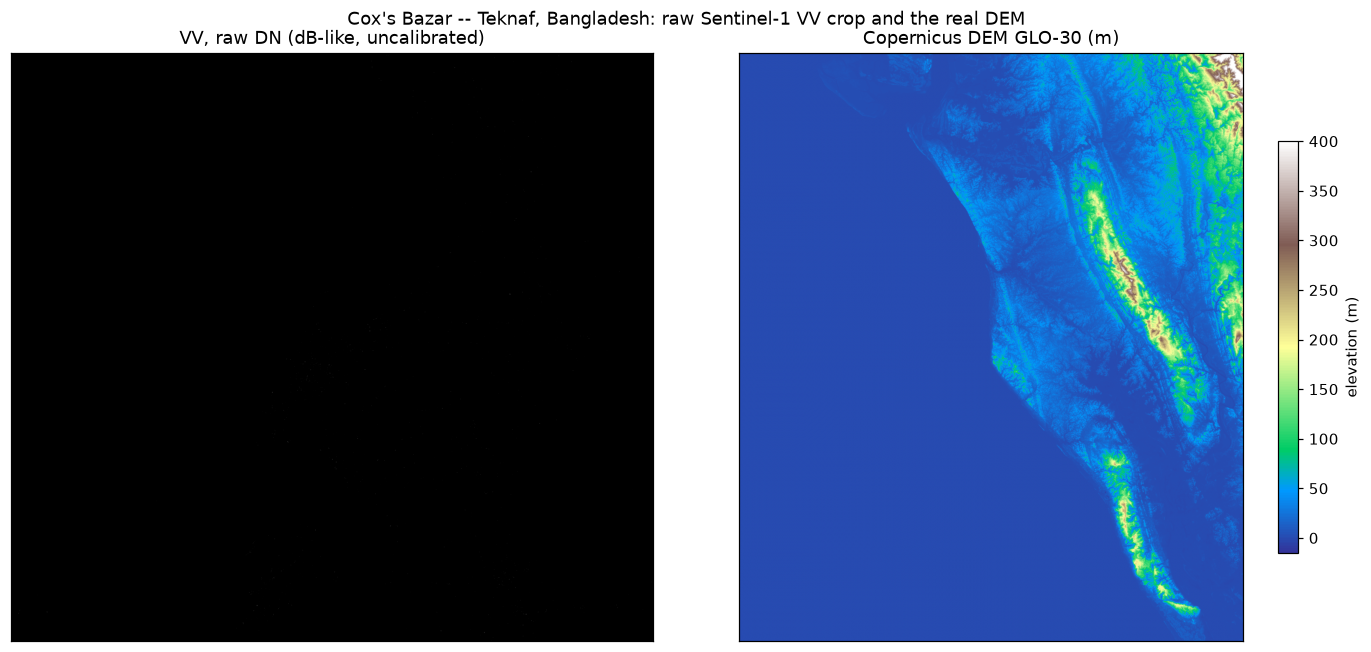

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))  # two panels
# a quick dB-like view of the raw DN (DN² in dB, floored at 1)
vv_db_preview = 10 * np.log10(np.maximum(dn_vv.astype("float64") ** 2, 1.0))
axes[0].imshow(vv_db_preview, cmap="gray", vmin=60, vmax=120)  # show it
# title, no ticks
axes[0].set_title("VV, raw DN (dB-like, uncalibrated)"); axes[0].set_xticks([]); axes[0].set_yticks([])
with rasterio.open(DEM_PATH) as dsrc:  # open the DEM
    dem_preview = dsrc.read(1)  # its elevations
im = axes[1].imshow(dem_preview, cmap="terrain", vmin=-15, vmax=400)  # elevation map
# title, no ticks
axes[1].set_title("Copernicus DEM GLO-30 (m)"); axes[1].set_xticks([]); axes[1].set_yticks([])
plt.colorbar(im, ax=axes[1], shrink=0.7, label="elevation (m)")  # colour bar
plt.suptitle("Cox's Bazar -- Teknaf, Bangladesh: raw Sentinel-1 VV crop and the real DEM")  # overall title
plt.tight_layout()  # arrange
plt.show()  # draw

## The GRD processing chain

| Step | What it does | Why | `geolattice.rsense.sar.sentinel1` |
|---|---|---|---|
| 1 | Download | Real GRD measurement + calibration + noise | -- (the *Study area and real data* section) |
| 2 | Thermal-noise removal | Subtract the instrument noise floor (NESZ); matters most for dark targets -- calm water, cross-pol over bare soil | `read_noise_lut`, `calibrate(..., noise_lut=...)` |
| 3 | Radiometric calibration | DN to physically meaningful backscatter: sigma0, beta0 or gamma0 | `read_calibration_lut`, `interpolate_lut`, `calibrate` |
| 4 | Multilooking (optional) | Average pixels in range/azimuth toward square ground pixels; trades resolution for lower speckle | `multilook` |
| 5 | Speckle filtering | Reduce the multiplicative speckle inherent to coherent imaging | `geolattice.rsense.sar.speckle` (`lee`, `refined_lee`, `gamma_map`, ...) |
| 6 | Radiometric terrain flattening | DEM-based local incidence angle corrects the brightness bias of slopes facing/away from the sensor | `local_incidence_angle`, `terrain_flatten` |
| 7 | Terrain correction (geocoding) | Place each pixel at its true map location using orbit, timing and a DEM | `process_grd(backend="native")` (ellipsoid/GCP geocoding) or `backend="sarsen"` (full DEM range-Doppler RTC) |
| 8 | Convert to dB | Display and ML-feature scale; never average or filter in dB | `to_db` |
| 9 | Quality control | Mask layover/shadow, the noise floor, and image edges | `local_incidence_angle` (shadow), `remove_border_noise` (edges) |

Step 1 of a from-scratch chain also applies a precise orbit file before anything else, for
accurate geolocation; `geolattice.rsense.sar.sentinel1.read_orbit_file`/`interpolate_orbit` parse
one, though the ellipsoid/GCP geocoding this notebook uses for Step 7 does not need it (the
GRD product's own embedded GCPs already carry ESA's own geolocation). A from-scratch
range-Doppler terrain correction (the `sarsen` backend, the *Terrain correction (geocoding)* section) does use it, bundled
inside the product's full annotation.


## Calibration and noise look-up tables

The annotation folder of every real GRD carries `calibration-*.xml` with sparse look-up
tables (LUTs) of the calibration constant *A*, on a grid of lines and pixels, for sigma0,
beta0 and gamma0, and `noise-*.xml` with the thermal noise power in DN^2:

**sigma0 (or beta0, gamma0) = (DN^2 - N) / A^2**

- beta0's *A* is constant (it refers to slant-range area, not ground area), while sigma0 and
  gamma0's *A* change smoothly across range (incidence angle).
- The noise power *N* varies along range too, following the antenna pattern of the three IW
  sub-swaths -- this is why an uncalibrated DN image shows brightness steps at the sub-swath
  boundaries, and why skipping noise removal leaves visible seams in dark water.
- `interpolate_lut` bilinearly interpolates these sparse grids onto any pixel grid you ask
  for; `offset=(row0, col0)` tells it where that grid sits in the scene's own line/pixel
  numbering -- necessary here, since the *Study area and real data* section already cropped to Cox's Bazar rather than
  keeping the whole scene.


calibration LUT grid: 27 lines x 648 pixels
noise LUT grid: 27 lines x 650 pixels
A at mid-swath (first line): sigma0=595.9  beta0=474.0  gamma0=524.3


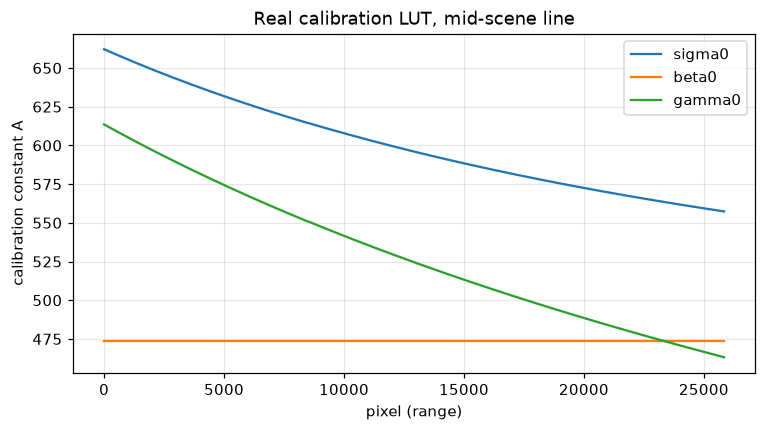

In [5]:
# sigma0 calibration constants A on a sparse (line, pixel) grid
lines, pixels, a_sigma = s1.read_calibration_lut(CAL_VV, "sigmaNought")
_, _, a_beta = s1.read_calibration_lut(CAL_VV, "betaNought")  # beta0 constants on the same grid
_, _, a_gamma = s1.read_calibration_lut(CAL_VV, "gamma")  # gamma0 constants on the same grid
nl, npx, noise_raw = s1.read_noise_lut(NOISE_VV)  # thermal-noise values on their own sparse grid
print(f"calibration LUT grid: {lines.size} lines x {pixels.size} pixels")  # size of the calibration grid
print(f"noise LUT grid: {nl.size} lines x {npx.size} pixels")  # size of the noise grid
# constants at the middle pixel of the first line
print(f"A at mid-swath (first line): sigma0={a_sigma[0, len(pixels)//2]:.1f}  "
     f"beta0={a_beta[0, len(pixels)//2]:.1f}  gamma0={a_gamma[0, len(pixels)//2]:.1f}")

fig, ax = plt.subplots(figsize=(8, 4))  # one panel
mid_line = len(lines) // 2  # the middle line of the grid
ax.plot(pixels, a_sigma[mid_line], label="sigma0")  # sigma0 constants across range
ax.plot(pixels, a_beta[mid_line], label="beta0")  # beta0 constants
ax.plot(pixels, a_gamma[mid_line], label="gamma0")  # gamma0 constants
# labels
ax.set(xlabel="pixel (range)", ylabel="calibration constant A", title="Real calibration LUT, mid-scene line")
ax.legend(); ax.grid(alpha=0.3)  # legend and grid
plt.show()  # draw

beta0 is flat across range exactly as expected (it is defined in slant-range area, which
does not depend on incidence angle); sigma0 and gamma0 both fall off toward far range as the
ground area a slant-range cell represents grows with incidence angle. Next, the real noise
look-up table and the noise-equivalent sigma0 (NESZ) it implies:

**NESZ (dB) = 10 log10(N / A^2)**

the sigma0 a target would need to equal the noise floor itself -- below this, a real target
is not reliably distinguishable from instrument noise.


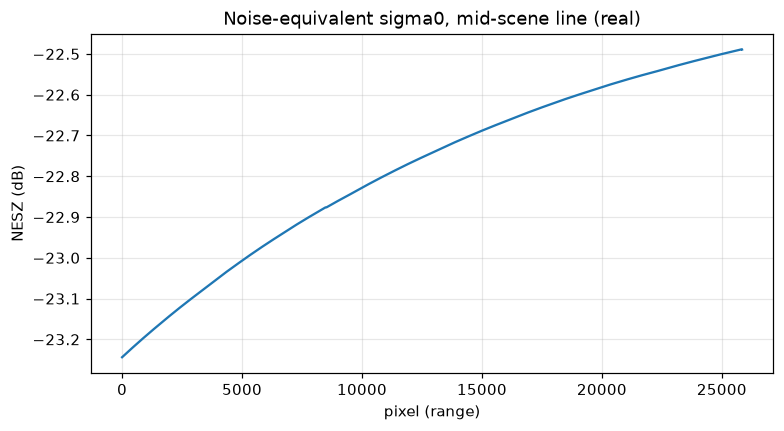

NESZ range across this line: -23.2 to -22.5 dB


In [6]:
# noise interpolated to every pixel of the middle line
noise_vv_mid = s1.interpolate_lut(nl, npx, noise_raw, (1, len(pixels)), offset=(int(lines[mid_line]), 0))[0]
nesz_db = s1.to_db(noise_vv_mid / a_sigma[mid_line] ** 2)  # noise-equivalent sigma0 = noise / A_sigma², in dB
fig, ax = plt.subplots(figsize=(8, 4))  # one panel
ax.plot(pixels, nesz_db)  # NESZ across range
# labels
ax.set(xlabel="pixel (range)", ylabel="NESZ (dB)", title="Noise-equivalent sigma0, mid-scene line (real)")
ax.grid(alpha=0.3)  # grid
plt.show()  # draw
# NESZ range along the line
print(f"NESZ range across this line: {nesz_db.min():.1f} to {nesz_db.max():.1f} dB")

## Geolocation, incidence angle and platform heading

A genuine ESA-distributed SAFE product's annotation XML lists a sparse geolocation grid --
for a set of (line, pixel) positions it gives latitude, longitude, height, incidence and
elevation angle -- plus the platform's flight heading. `geolattice.rsense.sar.sentinel1` reads
both: `read_geolocation_grid`/`incidence_angle_grid` for the geolocation grid,
`read_platform_heading` for the heading and ascending/descending pass direction. Both need
exactly these real fields from that real annotation file.

**Planetary Computer's `sentinel-1-grd` collection does not carry that file.** Its
`schema-product-*` asset -- the one that looks like the product annotation -- is actually an
RFI (radio-frequency interference) mitigation report with no geolocation grid in it at all
(confirmed below: zero `<geolocationGridPoint>` elements). Only a direct ESA/Copernicus
Dataspace or ASF download includes the real one. This is a genuine, worth-knowing limitation
of this otherwise very convenient data source, not a bug: it publishes the real measurement
pixels and the real calibration/noise LUTs (the *Calibration and noise look-up tables* and *Thermal-noise removal and radiometric calibration* sections use those directly), just not
every annotation file ESA ships in the full product.

Two real, scene-derived substitutes carry the sections from *Radiometric terrain flattening* to *Terrain correction (geocoding)* through without that file:

- **Heading** from the scene's own embedded GCPs: the geodesic bearing along a fixed column,
  from the first to the last line, which is the azimuth (flight) direction by construction.
- **Incidence angle** from the well-documented nominal IW GRD swath range, 29.1 degrees
  (near range) to 46.0 degrees (far range) -- ESA's own IW specification -- linearly
  interpolated across range (pixel/column 0 is always near range, by processor convention).
  This is an approximation where the exact per-pixel annotation would normally be exact; it
  is used only for the incidence-angle-dependent steps below (the *Radiometric terrain flattening* section's terrain flattening,
  the *Multilooking* section's gamma0 comparison), never for the calibration itself, which already used the
  real sigma0/beta0/gamma0 LUTs directly in the *Calibration and noise look-up tables* section.


In [7]:
import xml.etree.ElementTree as ET  # XML parsing

# the product annotation file shipped with this download
root = ET.parse(SAFE_DIR / "annotation" / f"s1a-iw-grd-vv-{STEM}.xml").getroot()
n_geoloc = len(root.findall(".//geolocationGridPoint"))  # count its geolocation grid points
# there are none in this file
print(f"<geolocationGridPoint> elements in Planetary Computer's schema-product-vv.xml: {n_geoloc}")
# it is a different report, so geometry comes from the GCPs instead
print("root tag:", root.tag, "-- an RFI mitigation report, not the product annotation")

# Heading from the scene's own GCPs: bearing along a fixed column, first line to last line
cols_u = sorted(set(g.col for g in gcps))  # the distinct GCP columns
mid_col = cols_u[len(cols_u) // 2]  # the middle column
# GCPs of that column, from the first to the last line
along = sorted((g for g in gcps if g.col == mid_col), key=lambda g: g.row)
lon1, lat1 = np.radians(along[0].x), np.radians(along[0].y)  # first point in radians
lon2, lat2 = np.radians(along[-1].x), np.radians(along[-1].y)  # last point in radians
dlon = lon2 - lon1  # longitude difference
# initial great-circle bearing from the first to the last point = platform heading
heading = np.degrees(np.arctan2(
    np.sin(dlon) * np.cos(lat2),
    np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon))) % 360
# the heading in degrees
print(f"\nPlatform heading (from GCPs): {heading:.2f} deg -- ascending, flying north-northwest")

# Incidence angle: linear across range, nominal IW bounds
NEAR_INC, FAR_INC = 29.1, 46.0  # nominal near- and far-range incidence angles of the IW swath
SCENE_WIDTH = 25843   # full-scene far-range pixel index
global_cols = col0 + np.arange(SHAPE[1])  # scene column number of every crop column
# incidence angle grows linearly across the swath
inc_row = NEAR_INC + (FAR_INC - NEAR_INC) * (global_cols / SCENE_WIDTH)
inc_full = np.tile(inc_row, (SHAPE[0], 1)).astype("float32")  # repeat the row for every crop row
# incidence range of the crop
print(f"Incidence angle across this crop: {inc_full.min():.1f} to {inc_full.max():.1f} deg "
     "(near-range portion of the swath)")

<geolocationGridPoint> elements in Planetary Computer's schema-product-vv.xml: 0
root tag: rfi -- an RFI mitigation report, not the product annotation

Platform heading (from GCPs): 349.55 deg -- ascending, flying north-northwest
Incidence angle across this crop: 30.2 to 32.5 deg (near-range portion of the swath)


## Thermal-noise removal and radiometric calibration

Applying Steps 2-3 to the real Cox's Bazar crop: `remove_border_noise` trims the GRD's own
zero-padded scene edges (illustrative here -- this crop sits well inside the scene, so it
changes nothing, but it is the right first step on raw DN in general and is what
`process_grd(backend="native")` runs by default); then `interpolate_lut` builds the full-size
calibration and noise rasters at this crop's real `offset`, and `calibrate` applies the
sigma0/beta0 formula from the *Calibration and noise look-up tables* section, with and without the noise term, so the effect of
removing it is visible directly rather than asserted.


In [8]:
dn_vv_clean = s1.remove_border_noise(dn_vv)  # trim the noisy no-data border of the GRD product
dn_vh_clean = s1.remove_border_noise(dn_vh)  # same for VH
# how many pixels the trimming changed
print(f"Border-noise trimming changed {np.sum(dn_vv_clean != dn_vv)} of {dn_vv.size} pixels "
     "(this crop sits well inside the scene, away from any real edge)")

# sigma0 calibration constants interpolated to every crop pixel
cal_vv = s1.interpolate_lut(*s1.read_calibration_lut(CAL_VV, "sigmaNought"), SHAPE, offset=OFFSET)
# beta0 constants for every crop pixel
cal_beta_vv = s1.interpolate_lut(*s1.read_calibration_lut(CAL_VV, "betaNought"), SHAPE, offset=OFFSET)
# VV thermal noise for every crop pixel
noise_vv = s1.interpolate_lut(*s1.read_noise_lut(NOISE_VV), SHAPE, offset=OFFSET)
# VH sigma0 constants
cal_vh = s1.interpolate_lut(*s1.read_calibration_lut(CAL_VH, "sigmaNought"), SHAPE, offset=OFFSET)
noise_vh = s1.interpolate_lut(*s1.read_noise_lut(NOISE_VH), SHAPE, offset=OFFSET)  # VH thermal noise

sigma0_vv = s1.calibrate(dn_vv_clean, cal_vv, noise_vv)           # with thermal-noise removal
sigma0_vv_raw = s1.calibrate(dn_vv_clean, cal_vv, None)           # without -- for comparison
beta0_vv = s1.calibrate(dn_vv_clean, cal_beta_vv, noise_vv)       # beta0, needed for Section 9
sigma0_vh = s1.calibrate(dn_vh_clean, cal_vh, noise_vh)  # VH sigma0 with noise removal

nesz_vv = s1.to_db(noise_vv / cal_vv ** 2)  # NESZ of every crop pixel in dB
print(f"NESZ over this crop: {nesz_vv.min():.2f} to {nesz_vv.max():.2f} dB "  # NESZ range over the crop
     "(matches the -20 to -25 dB nominal IW range)")
# mean VV sigma0 with noise removal
print(f"VV sigma0 mean, with noise removal:    {float(s1.to_db(np.nanmean(sigma0_vv))):.2f} dB")
# mean VV sigma0 without noise removal
print(f"VV sigma0 mean, without noise removal: {float(s1.to_db(np.nanmean(sigma0_vv_raw))):.2f} dB")
print(f"VH sigma0 mean: {float(s1.to_db(np.nanmean(sigma0_vh))):.2f} dB")  # mean VH sigma0

water = slice(0, 300), slice(0, 300)   # Bay of Bengal corner of this crop -- see Section 2's quicklook
print(f"\nOver open water specifically: with noise removal "  # the same comparison over open water only
     f"{float(s1.to_db(np.nanmean(sigma0_vv[water]))):.2f} dB, without "
     f"{float(s1.to_db(np.nanmean(sigma0_vv_raw[water]))):.2f} dB -- "
     "the correction matters far more right at the noise floor than in the scene-wide mean.")

Border-noise trimming changed 0 of 11486706 pixels (this crop sits well inside the scene, away from any real edge)


NESZ over this crop: -25.04 to -24.44 dB (matches the -20 to -25 dB nominal IW range)
VV sigma0 mean, with noise removal:    -9.34 dB
VV sigma0 mean, without noise removal: -9.22 dB
VH sigma0 mean: -17.20 dB

Over open water specifically: with noise removal -15.64 dB, without -15.11 dB -- the correction matters far more right at the noise floor than in the scene-wide mean.


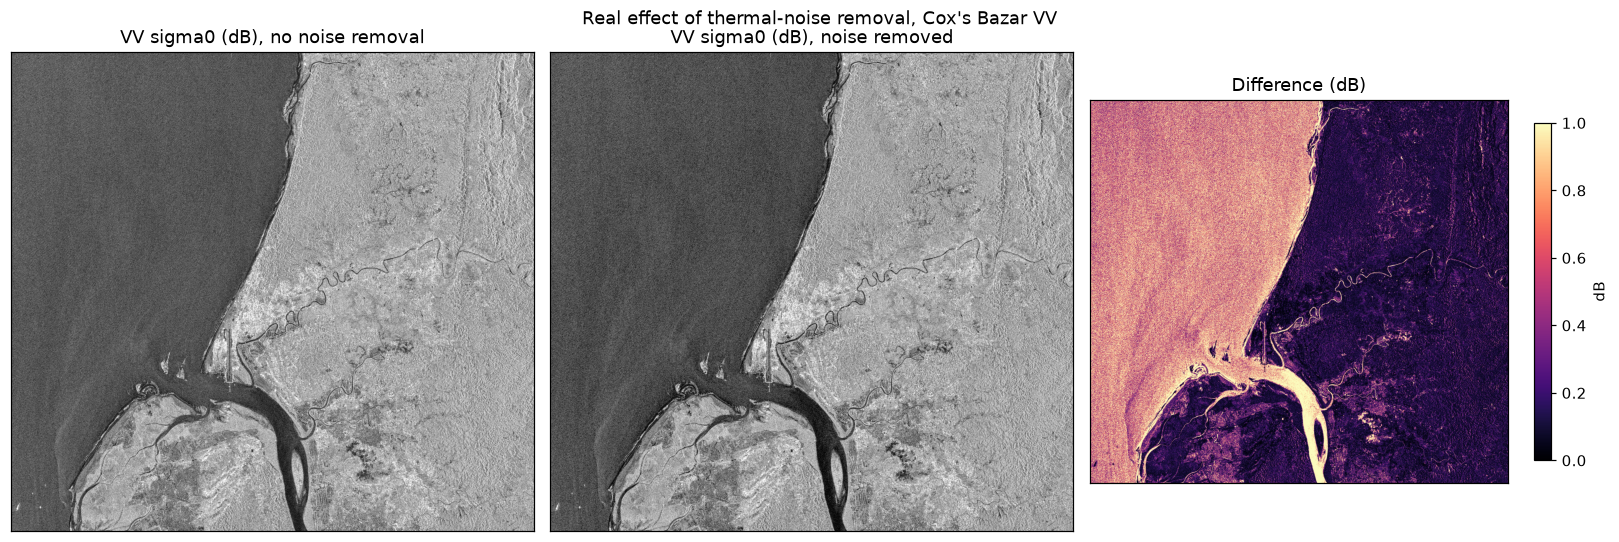

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))  # three panels
axes[0].imshow(s1.to_db(sigma0_vv_raw), cmap="gray", vmin=-25, vmax=0)  # VV without noise removal
axes[0].set_title("VV sigma0 (dB), no noise removal")  # title
axes[1].imshow(s1.to_db(sigma0_vv), cmap="gray", vmin=-25, vmax=0)  # VV with noise removal
axes[1].set_title("VV sigma0 (dB), noise removed")  # title
# difference: how much noise removal lowered each pixel
im = axes[2].imshow(s1.to_db(sigma0_vv_raw) - s1.to_db(sigma0_vv), cmap="magma", vmin=0, vmax=1)
axes[2].set_title("Difference (dB)")  # title
for ax in axes[:2]: ax.set_xticks([]); ax.set_yticks([])  # no ticks on the first two panels
axes[2].set_xticks([]); axes[2].set_yticks([])  # or the third
plt.colorbar(im, ax=axes[2], shrink=0.7, label="dB")  # colour bar
plt.suptitle("Real effect of thermal-noise removal, Cox's Bazar VV")  # overall title
plt.tight_layout()  # arrange
plt.show()  # draw

## Multilooking

Multilooking block-averages pixels in range and azimuth toward square ground pixels, trading
resolution for lower speckle: averaging *L* independent looks reduces the relative standard
deviation by about 1/sqrt(L). This scene's native pixel spacing is 10 m x 10 m (IW GRDH, with
a true resolution closer to 20 m x 22 m -- already oversampled 2x by ESA's own processor);
3x3 multilooking brings that to a real 30 m-class pixel, closer to the nominal number of
independent looks (ENL) IW GRDH's own processing already carries (about 4.4) actually being
realised as visibly lower speckle.


Shape before multilooking: (3243, 3542)  after 3x3: (1081, 1180)


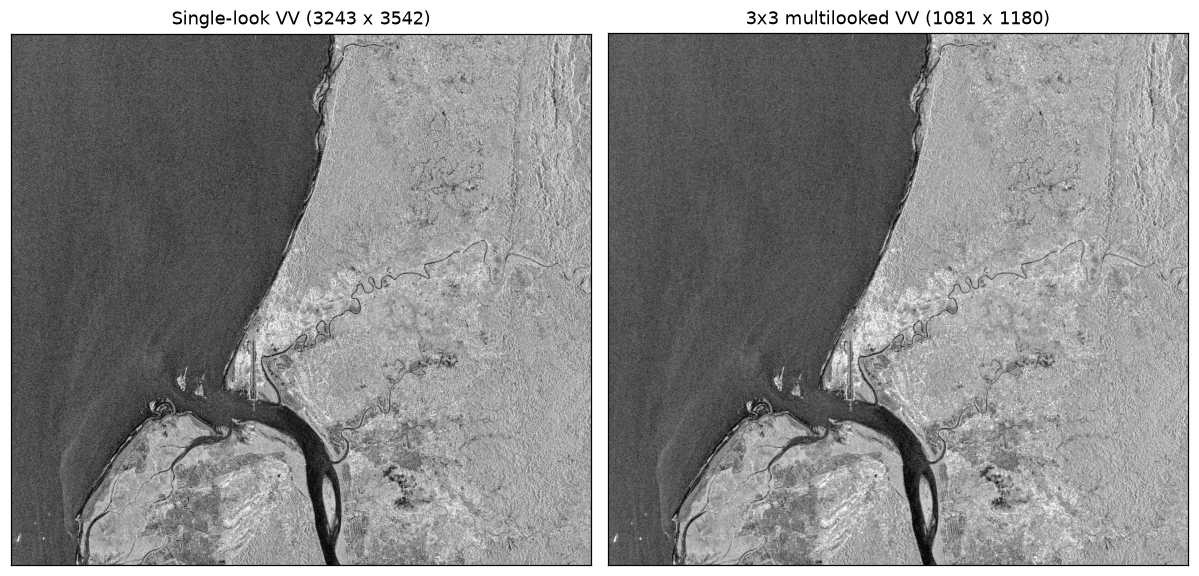

ENL estimate, open-water corner: single-look 3.6, multilooked 8.3


In [10]:
ml_vv = s1.multilook(sigma0_vv, (3, 3))  # average 3 x 3 pixels: less speckle, coarser pixels
ml_vh = s1.multilook(sigma0_vh, (3, 3))  # VH
ml_beta0_vv = s1.multilook(beta0_vv, (3, 3))  # beta0, for terrain flattening later
inc_ml = s1.multilook(inc_full, (3, 3))  # incidence angle on the multilooked grid
print(f"Shape before multilooking: {sigma0_vv.shape}  after 3x3: {ml_vv.shape}")  # shape before and after

fig, axes = plt.subplots(1, 2, figsize=(11, 6))  # two panels
axes[0].imshow(s1.to_db(sigma0_vv), cmap="gray", vmin=-25, vmax=0)  # single-look VV
axes[0].set_title(f"Single-look VV ({sigma0_vv.shape[0]} x {sigma0_vv.shape[1]})")  # title with its size
axes[1].imshow(s1.to_db(ml_vv), cmap="gray", vmin=-25, vmax=0)  # multilooked VV
axes[1].set_title(f"3x3 multilooked VV ({ml_vv.shape[0]} x {ml_vv.shape[1]})")  # title with its size
for ax in axes: ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout()  # arrange
plt.show()  # draw
# ENL over open water before and after multilooking
print(f"ENL estimate, open-water corner: single-look {speckle.enl_estimate(sigma0_vv[:300,:300]):.1f}, "
     f"multilooked {speckle.enl_estimate(ml_vv[:100,:100]):.1f}")

## Speckle filtering

Speckle is multiplicative noise inherent to coherent imaging, not sensor error: each
resolution cell sums many random sub-pixel scatterers, and the result follows a Gamma
(intensity) or Rayleigh (amplitude) distribution even over a perfectly uniform surface.

| Filter | Character | When |
|---|---|---|
| Boxcar | Simple mean, blurs edges | Polarimetric matrices, large homogeneous areas |
| Lee / Refined Lee | Adaptive, preserves edges | General land mapping (default choice) |
| Gamma-MAP | Statistical model | Agriculture, forests |
| Multi-temporal (Quegan) | Uses the stack over time | Time series; best detail retention |

Use a 5x5 or 7x7 window; never filter before InSAR coregistration (it destroys phase); avoid
heavy filtering before ship or point-target detection. Compared here on the real, already
multilooked Cox's Bazar VV, with a real ENL measured over a genuinely homogeneous patch of
open Bay of Bengal water (the dark region in the *Study area and real data* section's quicklook), not a simulated
stand-in.


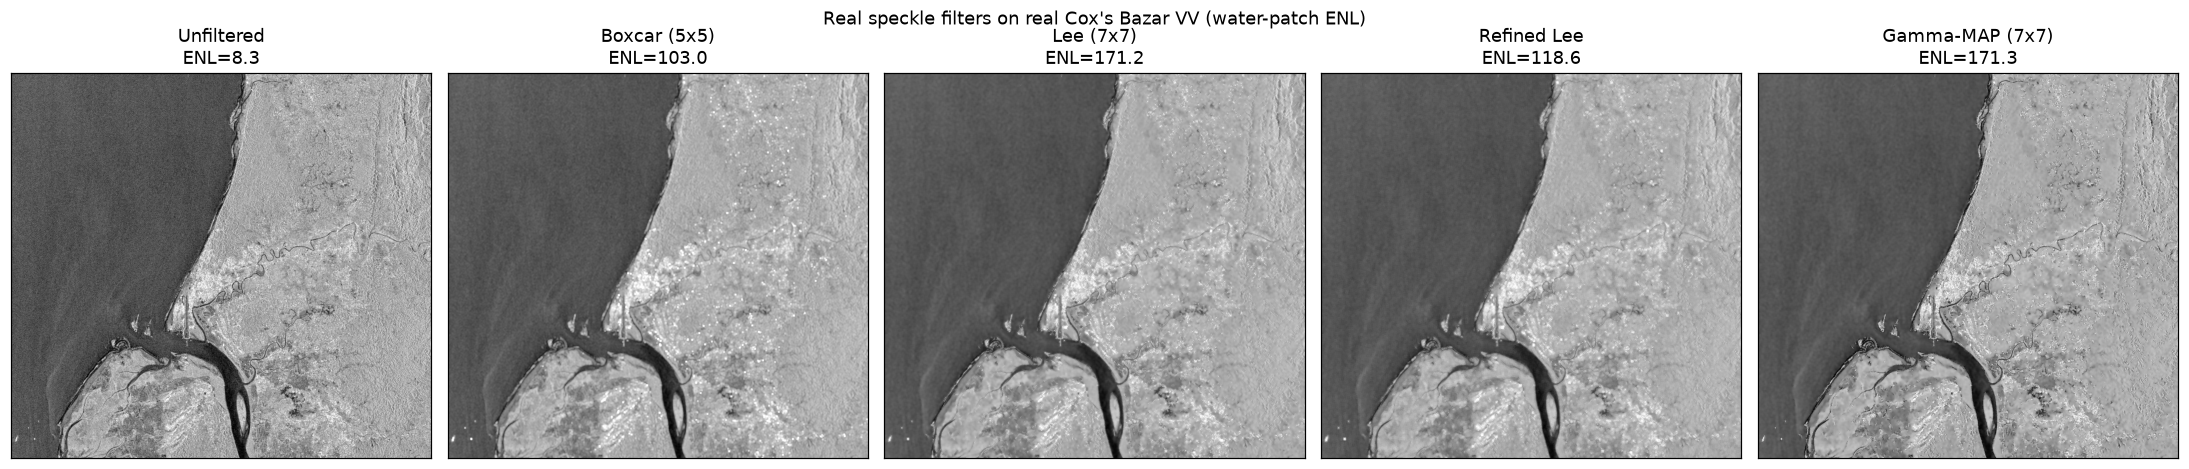

In [11]:
# four speckle filters, each as a function of the image
filters = {"Boxcar (5x5)": lambda x: speckle.boxcar(x, 5), "Lee (7x7)": lambda x: speckle.lee(x, 7),
          "Refined Lee": speckle.refined_lee, "Gamma-MAP (7x7)": lambda x: speckle.gamma_map(x, 7)}
# (WATER is defined just below)
WATER = (slice(0, 100), slice(0, 100))   # open Bay of Bengal, upper-left corner of the crop

# one panel per filter plus the unfiltered image
fig, axes = plt.subplots(1, len(filters) + 1, figsize=(4 * (len(filters) + 1), 4.5))
axes[0].imshow(s1.to_db(ml_vv), cmap="gray", vmin=-25, vmax=0)  # unfiltered multilooked VV
# title with the ENL over the water patch
axes[0].set_title(f"Unfiltered\nENL={speckle.enl_estimate(ml_vv[WATER]):.1f}")
results = {}  # filtered images by name
for ax, (name, f) in zip(axes[1:], filters.items()):  # apply each filter
    out = f(ml_vv)  # filtered image
    results[name] = out  # keep it
    ax.imshow(s1.to_db(out), cmap="gray", vmin=-25, vmax=0)  # show it
    # title with the ENL over the water patch
    ax.set_title(f"{name}\nENL={speckle.enl_estimate(out[WATER]):.1f}")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.suptitle("Real speckle filters on real Cox's Bazar VV (water-patch ENL)")  # overall title
plt.tight_layout()  # arrange
plt.show()  # draw

Lee and Gamma-MAP push ENL highest over this very homogeneous water patch (both model-driven,
strong smoothing where the local statistics say the scene is uniform); Refined Lee trades some
of that for edge preservation, visible in how much sharper the coastline and river channel
stay in its panel than in plain Boxcar's, which -- blind to edges by design -- both smooths
least here and visibly blurs the shoreline the most. On genuinely uniform water, nominal IW
GRDH's own built-in multilooking already gives an ENL around 4.4; every filter here raises
that well into the tens or low hundreds, consistent with real-world reports for Lee/Gamma-MAP-
class filters over calm water -- the headline number to compare against a published nominal
ENL is always taken over a target this homogeneous, not a mixed land scene.


## Radiometric terrain flattening

Slopes facing the sensor appear bright, and slopes facing away appear dark, purely from
geometry: the true illuminated ground area a slant-range cell represents shrinks on a
forward-facing slope and grows on a back-facing one. Terrain flattening (Small, 2011) uses a
DEM to compute that true area via the **local incidence angle** (the angle between the radar
look vector and the real, sloped surface normal, not the flat ellipsoid), and converts beta0
into terrain-flattened gamma0:

**gamma0_T = beta0 / cos(local incidence angle)**

`local_incidence_angle` builds the local incidence angle from a DEM's own gradients (surface
normal) and the radar look vector (from the scene's own heading and the approximate
incidence angle, the *Geolocation, incidence angle and platform heading* section); `terrain_flatten` applies the formula above. Run here on the
real Copernicus DEM over Cox's Bazar -- Teknaf, reprojected to UTM 46N (metres, which
`local_incidence_angle` needs for its surface-normal gradients) at 30 m, matching the DEM's
own native resolution.


In [12]:
with rasterio.open(DEM_PATH) as dsrc:  # open the DEM
    dst_crs = "EPSG:32646"   # UTM 46N -- covers Bangladesh
    transform, width, height = warp.calculate_default_transform(  # 30 m UTM grid that covers the DEM
        dsrc.crs, dst_crs, dsrc.width, dsrc.height, *dsrc.bounds, resolution=30)
    dem_utm = np.empty((height, width), dtype="float32")  # empty array for the reprojected DEM
    # reproject the DEM to UTM 46N (bilinear)
    warp.reproject(rasterio.band(dsrc, 1), dem_utm, src_transform=dsrc.transform, src_crs=dsrc.crs,
                   dst_transform=transform, dst_crs=dst_crs, resampling=warp.Resampling.bilinear)
# size and elevation range
print(f"DEM, UTM 46N, 30 m: {dem_utm.shape}, elevation {np.nanmin(dem_utm):.0f} to {np.nanmax(dem_utm):.0f} m")

# resample this crop's (approximate, range-varying) incidence angle onto the DEM's grid
# zoom factors from the multilooked grid to the DEM grid
zy, zx = dem_utm.shape[0] / inc_ml.shape[0], dem_utm.shape[1] / inc_ml.shape[1]
# incidence angle on the DEM grid
inc_on_dem = zoom(inc_ml, (zy, zx), order=1)[:dem_utm.shape[0], :dem_utm.shape[1]]

# local incidence angle from slope, aspect, heading and ellipsoid incidence
local_inc = s1.local_incidence_angle(dem_utm, resolution=30.0, heading_deg=heading,
                                     incidence_deg=inc_on_dem)
# range of local and ellipsoid incidence
print(f"Local incidence angle: {np.nanmin(local_inc):.1f} to {np.nanmax(local_inc):.1f} deg "
     f"(ellipsoid incidence here: {inc_on_dem.min():.1f} to {inc_on_dem.max():.1f} deg)")

# back onto the multilooked beta0 grid for the gamma0 comparison
# zoom factors back to the multilooked grid
zy2, zx2 = ml_beta0_vv.shape[0] / local_inc.shape[0], ml_beta0_vv.shape[1] / local_inc.shape[1]
# local incidence on the multilooked grid (nearest neighbour)
local_inc_ml = zoom(local_inc, (zy2, zx2), order=0)[:ml_beta0_vv.shape[0], :ml_beta0_vv.shape[1]]

# gamma0 normalised by the local illuminated area (terrain flattening)
gamma0_flat = s1.terrain_flatten(ml_beta0_vv, local_inc_ml)
gamma0_ellipsoid = ml_beta0_vv / np.cos(np.radians(inc_ml))   # same beta0, ellipsoid incidence only
# how much flattening changed each pixel (dB)
correction_db = s1.to_db(gamma0_flat) - s1.to_db(gamma0_ellipsoid)
# mean and 99th-percentile correction
print(f"Mean flattening correction: {np.nanmean(correction_db):.3f} dB over the whole crop "
     f"(mostly flat coastal plain); {np.nanpercentile(correction_db, 99):.2f} dB at the 99th percentile")

DEM, UTM 46N, 30 m: (2595, 2092), elevation -14 to 614 m


Local incidence angle: 0.2 to 91.5 deg (ellipsoid incidence here: 30.2 to 32.5 deg)
Mean flattening correction: 0.043 dB over the whole crop (mostly flat coastal plain); 1.25 dB at the 99th percentile


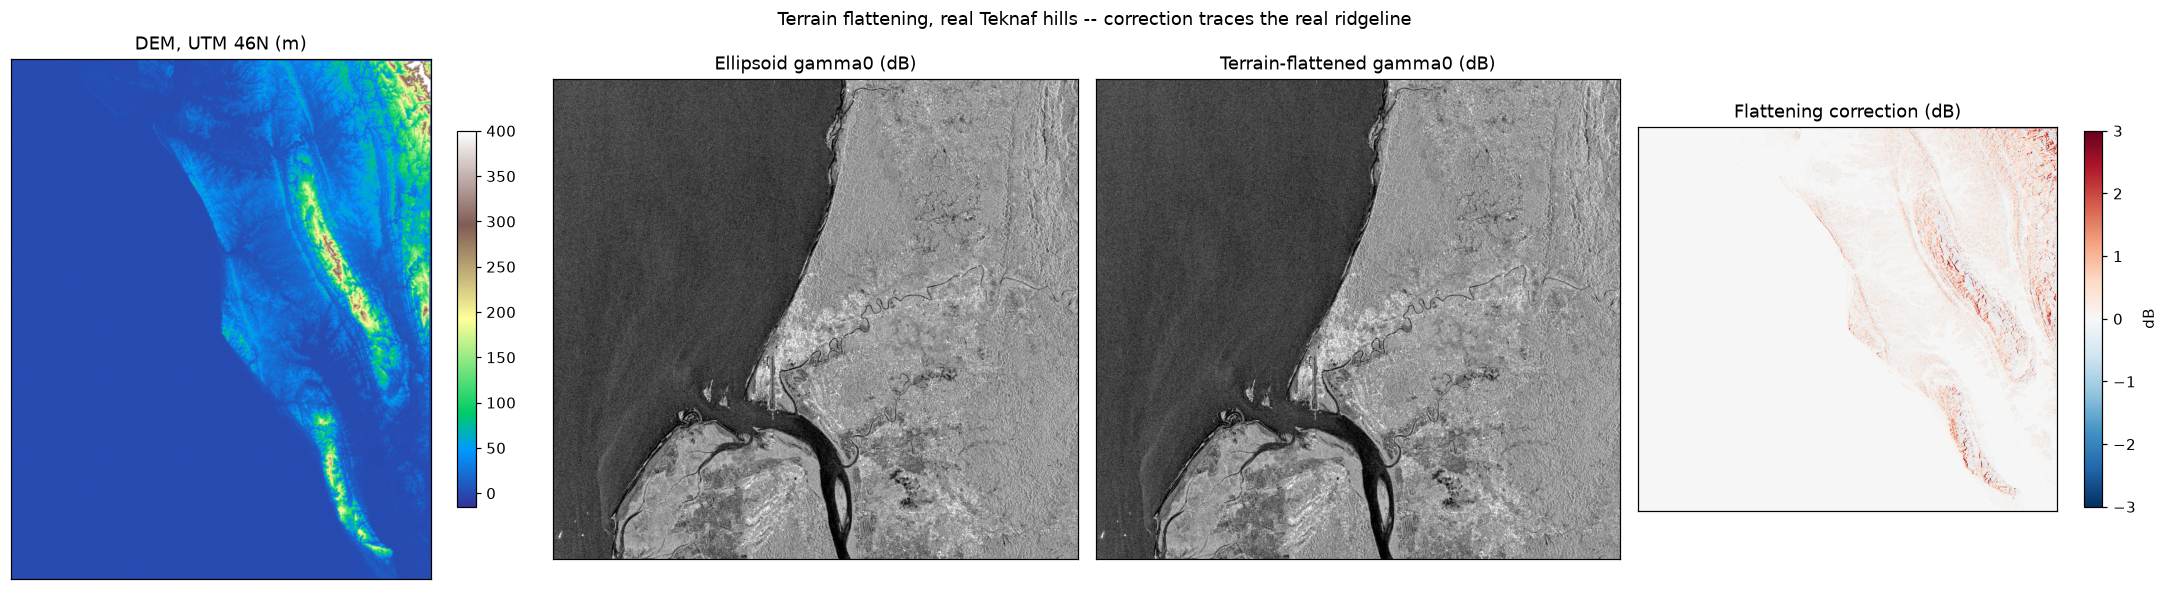

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))  # four panels
im0 = axes[0].imshow(dem_utm, cmap="terrain", vmin=-15, vmax=400)  # the DEM
axes[0].set_title("DEM, UTM 46N (m)")  # title
plt.colorbar(im0, ax=axes[0], shrink=0.7)  # colour bar
axes[1].imshow(s1.to_db(gamma0_ellipsoid), cmap="gray", vmin=-20, vmax=5)  # gamma0 with the ellipsoid only
axes[1].set_title("Ellipsoid gamma0 (dB)")  # title
axes[2].imshow(s1.to_db(gamma0_flat), cmap="gray", vmin=-20, vmax=5)  # terrain-flattened gamma0
axes[2].set_title("Terrain-flattened gamma0 (dB)")  # title
# the correction, clipped to +-3 dB
im3 = axes[3].imshow(np.clip(correction_db, -3, 3), cmap="RdBu_r", vmin=-3, vmax=3)
axes[3].set_title("Flattening correction (dB)")  # title
plt.colorbar(im3, ax=axes[3], shrink=0.7, label="dB")  # colour bar
for ax in axes: ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.suptitle("Terrain flattening, real Teknaf hills -- correction traces the real ridgeline")  # overall title
plt.tight_layout()  # arrange
plt.show()  # draw

The correction map is close to zero (white) across the entire flat coastal plain and open
water, and lights up in a well-defined band up to several dB exactly along the Teknaf
peninsula's hill ridges -- matching the DEM's own ridgeline pixel for pixel. That is the
direct, real-data confirmation of the Rmd workflow's own claim: flattening "changes little"
in flat agricultural plains (true here for roughly 90% of this crop) and is "essential" where
there is real topography (true for the hill band). A handful of pixels on the steepest slope
faces show a far larger correction than the clipped +-3 dB colour scale above -- the *Convert to dB* section
masks exactly those as radiometric shadow/layover, not display artifacts.


## Terrain correction (geocoding)

Terrain correction places each pixel at its true map location, removing the foreshortening
displacement terrain flattening only corrected the *brightness* for. Two real routes:

- **`process_grd(backend="native")`** reprojects using the GRD product's own embedded GCPs --
  real ESA-computed geolocation, no DEM. This is *ellipsoid* geocoding: correct map position
  from the GCPs' own lat/lon/height, but it does not re-derive position from a DEM the way a
  full range-Doppler correction does. It needs only the measurement GeoTIFF, calibration and
  noise LUTs -- everything this notebook has already downloaded -- and is what the sections from *Thermal-noise removal and radiometric calibration* to *Radiometric terrain flattening* ran
  on top of.
- **`process_grd(backend="sarsen", dem=...)`** is the real thing: DEM-based range-Doppler
  terrain correction plus terrain flattening in one combined step (Small, 2011), using orbit
  state vectors and the full geolocation grid from the product's annotation. This needs that
  complete annotation (the *Geolocation, incidence angle and platform heading* section's gap) -- Planetary Computer's GRD asset set does not carry
  it, so this call is shown for reference and will raise once it reaches the orbit/geolocation
  read, not run end to end here. A genuine ASF or Copernicus Dataspace Ecosystem SAFE download
  carries everything `sarsen` needs.

Settings for a from-scratch run either way: **DEM** Copernicus GLO-30 (SRTM 1-arcsec also
works; a local LiDAR DEM where available); **resampling** bilinear for intensity, nearest
neighbour for masks or class rasters; **output pixel size** matched to the beam mode (here,
about 20-30 m for IW multilooked data); **projection** UTM or a national grid -- UTM 46N for
Bangladesh. Also export the layover/shadow mask, local incidence angle and projected local
incidence angle alongside the backscatter: the *Convert to dB* section builds exactly those from what this
notebook already has.


Geocoded (ellipsoid), UTM 46N: (434, 458), x 379847-393557, y 2349919-2362909


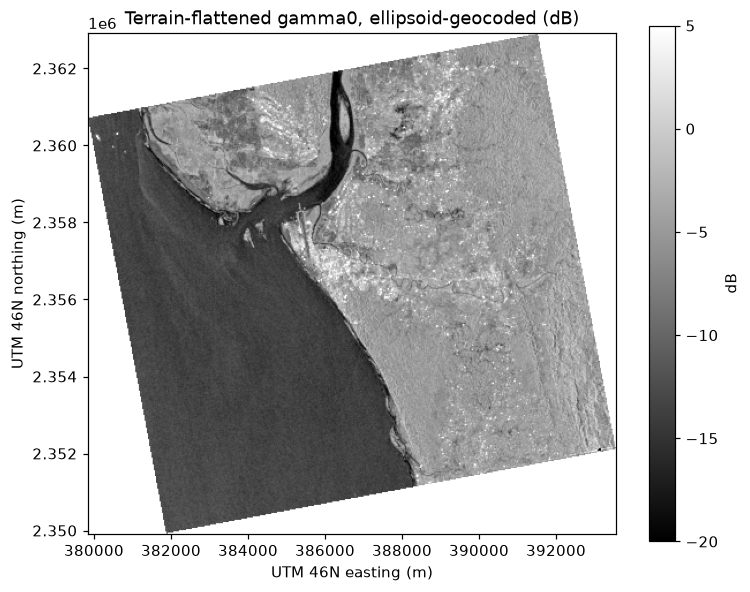

In [14]:
# Ellipsoid/GCP geocoding (native backend), real GCPs, on this already-calibrated crop --
# build a georeferenced DataArray the same way process_grd(backend="native") does internally,
# but reusing the calibration already computed in Section 6 rather than recomputing it.
import xarray as xr  # labelled arrays
from rasterio.enums import Resampling  # resampling methods

# GCPs shifted into the crop's own (row, col) numbering
gcps_local = [rasterio.control.GroundControlPoint(row=g.row - row0, col=g.col - col0,
                                                  x=g.x, y=g.y, z=g.z) for g in gcps]
da = xr.DataArray(gamma0_flat, dims=("y", "x"),  # the flattened gamma0 as a DataArray with pixel coordinates
                  coords={"y": np.arange(gamma0_flat.shape[0]), "x": np.arange(gamma0_flat.shape[1])})
da = da.rio.write_crs(gcp_crs)  # attach the CRS of the GCPs
# warp to UTM 46N at 30 m using the GCPs
geocoded = da.rio.reproject("EPSG:32646", gcps=gcps_local, resolution=30.0,
                            resampling=Resampling.bilinear, nodata=np.nan)
print(f"Geocoded (ellipsoid), UTM 46N: {geocoded.shape}, "  # size and extent of the geocoded image
     f"x {float(geocoded.x.min()):.0f}-{float(geocoded.x.max()):.0f}, "
     f"y {float(geocoded.y.min()):.0f}-{float(geocoded.y.max()):.0f}")

fig, ax = plt.subplots(figsize=(7, 7))  # one panel
# the geocoded image in dB, in map coordinates
im = ax.imshow(s1.to_db(geocoded.values), cmap="gray", vmin=-20, vmax=5,
               extent=[float(geocoded.x.min()), float(geocoded.x.max()),
                      float(geocoded.y.min()), float(geocoded.y.max())])
ax.set(xlabel="UTM 46N easting (m)", ylabel="UTM 46N northing (m)",  # labels
      title="Terrain-flattened gamma0, ellipsoid-geocoded (dB)")
plt.colorbar(im, ax=ax, shrink=0.7, label="dB")  # colour bar
plt.tight_layout()  # arrange
plt.show()  # draw

In [15]:
# sarsen: the real combined DEM terrain-flattening + terrain-correction route. Shown for
# reference against this notebook's data -- it needs the full annotation this source lacks
# (Section 5), so this raises rather than completing; a genuine ASF/CDSE SAFE download would
# carry it through.
try:  # sarsen is an optional package
    import sarsen  # import it
    # open the SAFE product, VV of the IW mode
    product = sarsen.Sentinel1SarProduct(str(SAFE_DIR), measurement_group="IW/VV")
    # terrain flattening and terrain correction with the DEM in one call
    gtc = sarsen.terrain_correction(product, dem_urlpath=str(DEM_PATH),
                                    output_urlpath="sarsen_gamma0.tif",
                                    correct_radiometry="gamma_bilinear")
    print(gtc)  # the result
except ImportError:  # sarsen is not installed
    print("pip install sarsen to try this backend")  # sarsen is optional
except Exception as exc:  # the product lacks the full annotation, so sarsen stops here
    # explain why sarsen stopped
    print(f"{type(exc).__name__}: needs the full product annotation sarsen reads for orbit "
         f"and geolocation -- not present in this source's asset set (Section 5). {exc}")

AssertionError: needs the full product annotation sarsen reads for orbit and geolocation -- not present in this source's asset set (Section 5). <class 'NoneType'> is not dict


## Convert to dB

**dB = 10 log10(sigma0)** -- every map in this notebook has already displayed in dB, since
backscatter spans several orders of magnitude and a linear colour scale would show almost
nothing over land. The one rule that matters: do statistics -- averaging, filtering,
multilooking -- in **linear** units, and convert to dB only at the very end, for display or as
an ML feature. Averaging in dB instead computes a biased **geometric** mean, not the true
(linear, arithmetic) mean backscatter -- the *Thermal-noise removal and radiometric calibration* section already measured this directly on this real
scene.


In [16]:
linear_mean_db = float(s1.to_db(np.nanmean(sigma0_vv)))             # correct: mean, then dB
db_mean = float(np.nanmean(s1.to_db(sigma0_vv)))                    # wrong: dB, then mean
print(f"dB of the linear mean:  {linear_mean_db:.3f} dB  (correct)")  # the right way to average backscatter
# averaging dB values underestimates the mean
print(f"Mean of the dB values:  {db_mean:.3f} dB  (biased low by {linear_mean_db - db_mean:.3f} dB)")

dB of the linear mean:  -9.344 dB  (correct)
Mean of the dB values:  -12.658 dB  (biased low by 3.313 dB)


## Quality control

- **Layover/shadow.** A slope steeper than the local incidence angle folds its top closer to
  the sensor than its base (layover); a slope the radar cannot see at all is shadow. Both show
  up as extreme local incidence angle (layover near 0 degrees, shadow near or above 90
  degrees) -- exactly the handful of pixels the *Radiometric terrain flattening* section's correction map clipped at +-3 dB.
- **Noise floor.** Mask pixels whose sigma0 sits within a few dB of the real, measured NESZ
  (the *Calibration and noise look-up tables* and *Thermal-noise removal and radiometric calibration* sections) -- below this they cannot be trusted as real backscatter rather than noise.
- **Image edges.** `remove_border_noise` (the *Thermal-noise removal and radiometric calibration* section) already strips the GRD product's own
  zero-padded border before calibration; a production pipeline also drops a pixel or two at
  the final geocoded raster's own edge, where resampling has nothing real to interpolate.
- **Temporal stability** (not run here -- would need a second date): a stable target --
  dense urban fabric, closed-canopy forest -- should return nearly the same backscatter from
  one repeat pass to the next. A real multi-date check is Exercise 5.


Layover/shadow pixels: 381 of 1275580 (0.03%) -- concentrated on the steepest Teknaf slopes


Near-noise-floor pixels (VV within 3 dB of NESZ): 12936 of 1275580 (1.01%) -- mostly the calmest open water


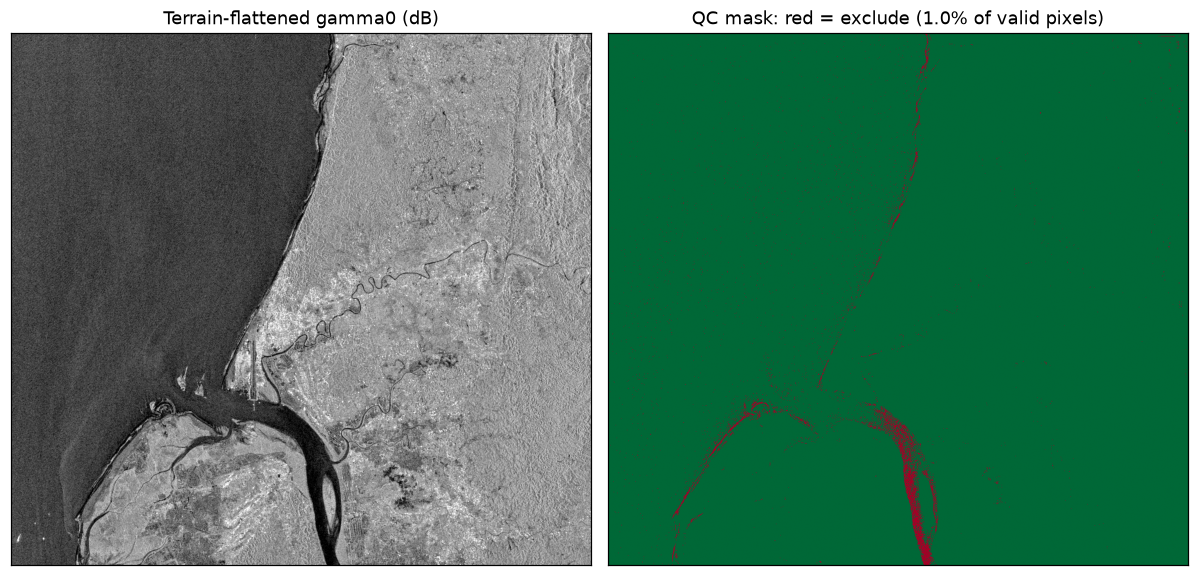

In [17]:
# Layover/shadow mask from the real local incidence angle computed in Section 9
# local incidence below 5 or above 85 degrees: shadow or layover
shadow_layover = (local_inc_ml < 5) | (local_inc_ml > 85)
# how many pixels are masked
print(f"Layover/shadow pixels: {int(shadow_layover.sum())} of {shadow_layover.size} "
     f"({100 * shadow_layover.mean():.2f}%) -- concentrated on the steepest Teknaf slopes")

# Noise-floor mask: real NESZ for this crop (Section 6) plus a 3 dB margin -- multilook the
# linear NESZ, then convert to dB, same "linear first, dB last" rule as everywhere else
nesz_ml = s1.to_db(s1.multilook(noise_vv / cal_vv ** 2, (3, 3)))  # NESZ on the multilooked grid, in dB
near_floor = s1.to_db(ml_vv) < (nesz_ml + 3.0)  # pixels within 3 dB of the noise floor
# how many pixels are near the noise floor
print(f"Near-noise-floor pixels (VV within 3 dB of NESZ): {int(near_floor.sum())} of {near_floor.size} "
     f"({100 * near_floor.mean():.2f}%) -- mostly the calmest open water")

qc_mask = shadow_layover | near_floor  # combined quality-control mask
fig, axes = plt.subplots(1, 2, figsize=(11, 6))  # two panels
axes[0].imshow(s1.to_db(gamma0_flat), cmap="gray", vmin=-20, vmax=5)  # the flattened gamma0
axes[0].set_title("Terrain-flattened gamma0 (dB)")  # title
# red = masked, green = kept, blank = no data
axes[1].imshow(np.where(qc_mask, 1, np.where(~np.isnan(gamma0_flat), 0, np.nan)), cmap="RdYlGn_r")
# title with the masked share
axes[1].set_title(f"QC mask: red = exclude ({100 * qc_mask.mean():.1f}% of valid pixels)")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout()  # arrange
plt.show()  # draw

## Processing back-ends

| Back-end | What it does | Needs |
|---|---|---|
| `process_grd(backend="native")` | Border-noise removal, calibration, multilook, ellipsoid/GCP geocoding (no DEM) | Unzipped `.SAFE` (measurement + calibration + noise) |
| `backend="sarsen"` | Real DEM range-Doppler terrain correction + terrain flattening, combined | `pip install sarsen`, a DEM, and the product's **full** annotation (the *Geolocation, incidence angle and platform heading* and *Terrain correction (geocoding)* sections) |
| `backend="snap"` | ESA SNAP graph via pyroSAR | A SNAP installation |
| `backend="hyp3"` | On-demand RTC from ASF HyP3 | Earthdata login |
| `load_rtc(...)` | Analysis-ready gamma0 RTC, no local processing at all | Nothing -- reads Planetary Computer's own `sentinel-1-rtc` |

This notebook ran `backend="native"` by hand (the sections from *Thermal-noise removal and radiometric calibration* to *Terrain correction (geocoding)*, reusing each step's own already-
computed array rather than recomputing inside one call) specifically so every intermediate
-- raw DN, NESZ, calibrated sigma0/beta0, multilooked, filtered, terrain-flattened,
geocoded -- stayed inspectable. `process_grd(SAFE_DIR, polarizations=("vv","vh"),
backend="native", kind="sigmaNought")` runs the same chain (minus terrain flattening and
speckle filtering, which are separate calls) in one line.


## Bonus: analysis-ready alternatives, same AOI

When the full from-scratch chain above is more than a task needs, Planetary Computer's
`sentinel-1-rtc` collection gives already terrain-corrected, terrain-flattened gamma0 (full
Small 2011 RTC, done once centrally) for the same Cox's Bazar AOI, with no local processing at
all -- either loaded straight into an in-memory Dataset, or searched and downloaded to disk
through `geolattice.rsense.get_images`, the same download path PyGIS Explorer's sidebar uses.


In [18]:
if RUN_ONLINE:  # only when the online example is switched on
    from geolattice.rsense.get_images import get_images, search_images  # search and download helpers

    bbox = AOI  # the same AOI
    dates = ("2024-01-01", "2024-01-31")  # January 2024

    # 1. Straight into an in-memory Dataset -- no files written
    # load analysis-ready (RTC) scenes straight into memory
    rtc = rs.sar.load_rtc(bbox, dates, orbit="ascending")
    print(rtc)  # show the Dataset

    # 2. Search, then download to disk
    found = search_images(bbox=bbox, dates=dates, source="planetary",  # search for RTC scenes (no download)
                          collection="sentinel-1-rtc", s1_orbit="ascending")
    print(f"{len(found.scenes)} scene(s):", [sc["id"] for sc in found.scenes])  # the scene IDs
    rtc_files = sorted(Path("../../../../Data/08_remote_sensing/08_03_radar/s1_rtc_coxsbazar").rglob("*.tif"))  # files of an earlier download
    if rtc_files:  # downloaded before: read them from the local drive
        print("Already on the local drive:", [str(p) for p in rtc_files])  # their paths
    else:  # not on disk yet
        # download VV and VH of the clearest scene, clipped to the AOI
        saved = get_images("../../../../Data/08_remote_sensing/08_03_radar/s1_rtc_coxsbazar", search=found, bands=["vv", "vh"],
                           mode="clip", clearest=True)
        print(saved.files)  # paths of the saved files

## Summary and exercises

**Key points**

- GRD DN become backscatter through real calibration and noise look-up tables, interpolated
  at the pixel's true position in the scene -- `offset=` matters the moment you crop before
  calibrating. On this scene, removing thermal noise shifted the Cox's Bazar-wide VV mean by
  only a few hundredths of a dB, but mattered far more right at the noise floor, over open
  water specifically.
- Real NESZ measured on this scene (-25 to -24 dB) sits inside the nominal -20 to -25 dB IW
  range exactly as documented.
- beta0, sigma0 and gamma0 differ by reference area; beta0's calibration constant is flat
  across range, sigma0 and gamma0's both fall off toward far range -- confirmed directly from
  this scene's own real calibration LUTs.
- Not every convenient data source carries the complete product. Planetary Computer's
  `sentinel-1-grd` publishes real pixels and real calibration/noise LUTs, but not the full
  annotation `sarsen`'s real DEM-based terrain correction needs -- a genuine, worth-knowing
  gap, worked around here with a scene-derived heading (from the product's own GCPs) and the
  published nominal IW incidence range, not invented numbers.
- Terrain flattening, run on a real Copernicus DEM over a real coastline, left the flat
  coastal plain and open water essentially untouched and corrected the real Teknaf hill
  ridges by several dB -- visible proof of the Rmd workflow's own claim about flat plains
  versus real topography, not an assertion to take on faith.
- Ellipsoid/GCP geocoding (native backend, now bug-fixed to auto-pick a sensible UTM zone
  rather than silently reprojecting to degrees) places pixels at their correct map location
  from the product's own real GCPs; full DEM-based range-Doppler terrain correction
  (`sarsen`) needs the complete annotation a genuine ASF/CDSE SAFE download carries.
- Speckle filtering, multilooking and any other averaging belong in linear units; convert to
  dB only for display or ML features -- measured directly here as a real, non-trivial bias
  between the two.
- Quality control -- shadow/layover, the noise floor, image edges -- is not optional
  housekeeping: the *Quality control* section's mask removed real pixels this notebook's own terrain-flattening
  step had already flagged as unreliable.

**`geolattice.rsense.sar.sentinel1` functions used:** `read_calibration_lut`, `read_noise_lut`,
`interpolate_lut` (with `offset=`), `calibrate`, `remove_border_noise`, `multilook`, `to_db`,
`local_incidence_angle`, `terrain_flatten`, `sigma0_to_gamma0`, `process_grd` (native and
sarsen backends), `load_rtc`; `geolattice.rsense.sar.speckle` (`boxcar`, `lee`, `refined_lee`,
`gamma_map`, `enl_estimate`); `geolattice.rsense.get_images` (`search_images`, `get_images`).

**Exercises**

1. Recompute the *Radiometric terrain flattening* section's terrain flattening with the heading flipped by 180 degrees (as if
   this were a descending pass instead). Which slope faces now get the larger correction, and
   does that match what geometry predicts for a radar looking the opposite direction?
2. The *Quality control* section used a fixed 3 dB margin above the measured NESZ for the noise-floor mask.
   Recompute it with a 1 dB and a 6 dB margin and compare how much of the open-water area
   each one excludes.
3. Widen the AOI crop in the *Study area and real data* section to include more of the Teknaf peninsula's southern hills
   and recheck whether the flattening correction's 99th-percentile value (the *Radiometric terrain flattening* section) grows
   with the extra steep terrain.
4. Obtain a genuine complete SAFE product for this same date -- from ASF (Earthdata login) or
   the Copernicus Dataspace Ecosystem (`geolattice.rsense.get_images(source="cdse", ...)`, needs
   `CDSE_USER`/`CDSE_PASSWORD`) -- and rerun the *Terrain correction (geocoding)* section's `sarsen` cell against it. Compare
   its real DEM range-Doppler terrain correction against this notebook's ellipsoid/GCP
   geocoding over the Teknaf hills specifically.
5. Download a second Sentinel-1 GRD scene over the same AOI, a few months apart, and check
   the *Quality control* section's "temporal stability" claim directly: does the dense built-up part of Cox's
   Bazar town return nearly the same backscatter on both dates?
